# ViT-B/16 Fine-tuning on HaGRID (Kaggle 30K Sample)

This notebook fine-tunes a Vision Transformer (ViT-B/16) on the HaGRID Kaggle sample dataset for gesture recognition.

**Dataset:** [HaGRID Sample 30K (384p)](https://www.kaggle.com/datasets/innominate817/hagrid-sample-30k-384p)
- Size: ~1.5 GB
- Classes: 18 gesture types
- Images: ~30,000

**Model:** ViT-B/16 (ImageNet pretrained, 224×224 input)

**Expected Training Time:** ~20-40 minutes on GPU

**Steps:**
1. Load Kaggle dataset from folder structure
2. Create PyTorch DataLoader with augmentation
3. Fine-tune ViT-B/16 for 10 epochs
4. Evaluate on test set
5. Visualize training curves, confusion matrix, and sample predictions

In [1]:
%pip install timm scikit-learn opendatasets matplotlib seaborn pandas torchvision

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
from pathlib import Path
from collections import defaultdict
import random

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from torchvision.datasets import ImageFolder
import timm
from tqdm import tqdm
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Set random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)

# Device setup
device = torch.device('mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

DATASET_LINK = "https://www.kaggle.com/datasets/innominate817/hagrid-sample-30k-384p"
MODEL_CHECKPOINT = Path('./checkpoints/best_model.pth')
MODEL_CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)

# Training parameters
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 3e-5
WEIGHT_DECAY = 0.01
IMG_SIZE = 224
NUM_CLASSES = None  # Will be set after exploring dataset

Using device: mps


### Setup Dataset

In [3]:
import os
import opendatasets as od

# Auto-detect dataset path (handles Kaggle's variable nested directory structure)
def find_hagrid_path(base_path='./data'):
    """Recursively find the hagrid_30k directory"""
    base = Path(base_path)
    if not base.exists():
        return None
    
    # Search for hagrid_30k folder up to 5 levels deep
    for pattern in ['**/hagrid_30k', '*/hagrid_30k', '*/*/hagrid_30k', '*/*/*/hagrid_30k', '*/*/*/*/hagrid_30k']:
        matches = list(base.glob(pattern))
        if matches:
            return matches[0]
    
    return None

# Find dataset path automatically
DATASET_ROOT = find_hagrid_path()
if DATASET_ROOT is None:
    # Fallback to expected path
    DATASET_ROOT = Path('./data/hagrid-sample-30k-384p/hagrid_30k')
    print(f"Dataset path not found automatically. Expected at: {DATASET_ROOT}")
else:
    print(f"✓ Found dataset at: {DATASET_ROOT}")

# Download dataset if not already present
if not DATASET_ROOT.exists():
    od.download(DATASET_LINK, data_dir=DATASET_ROOT.parent.parent)
    DATASET_ROOT = DATASET_ROOT.parent / 'hagrid-sample-30k-384p/hagrid_30k'

    os.listdir(DATASET_ROOT)
else:
    print("Dataset found")

Dataset path not found automatically. Expected at: data/hagrid-sample-30k-384p/hagrid_30k
Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username:

  neiltaisonrigaud


Your Kaggle Key:

  ········


Dataset URL: https://www.kaggle.com/datasets/innominate817/hagrid-sample-30k-384p


100%|████████████████████████████████████████████████████████████████████████████████| 823M/823M [01:22<00:00, 10.5MB/s]


In [4]:
# Explore dataset structure
if not DATASET_ROOT.exists():
    raise FileNotFoundError(f"Dataset not found at {DATASET_ROOT}. "
                           "Download from https://www.kaggle.com/datasets/innominate817/hagrid-sample-30k-384p "
                           "and extract to ./data/")

# Count images per gesture class (handles train_val_<gesture> naming)
gesture_dirs = sorted([d for d in DATASET_ROOT.iterdir() if d.is_dir() and not d.name.startswith('.')])
image_counts = {}
total_images = 0

for gesture_dir in gesture_dirs:
    images = list(gesture_dir.glob('*.jpg')) + list(gesture_dir.glob('*.png'))
    if len(images) > 0:
        # Remove 'train_val_' prefix from folder names for cleaner class names
        gesture_name = gesture_dir.name.replace('train_val_', '')
        image_counts[gesture_name] = len(images)
        total_images += len(images)

NUM_CLASSES = len(image_counts)
class_names = sorted(image_counts.keys())

print(f"Found {NUM_CLASSES} gesture classes with {total_images} total images")
print("\nImages per class:")
for cls in class_names:
    print(f"  {cls}: {image_counts[cls]}")
print(f"Total: {total_images}")

Found 18 gesture classes with 31833 total images

Images per class:
  call: 1763
  dislike: 1783
  fist: 1735
  four: 1805
  like: 1732
  mute: 1811
  ok: 1750
  one: 1778
  palm: 1770
  peace: 1769
  peace_inverted: 1742
  rock: 1736
  stop: 1748
  stop_inverted: 1803
  three: 1751
  three2: 1737
  two_up: 1855
  two_up_inverted: 1765
Total: 31833


In [5]:
# Data transforms
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Custom dataset class to handle 'train_val_' prefix in folder names
class HaGRIDDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = Path(root_dir)
        self.transform = transform
        self.samples = []
        self.classes = []
        self.class_to_idx = {}
        
        # Collect all gesture folders and images
        gesture_dirs = sorted([d for d in self.root_dir.iterdir() 
                              if d.is_dir() and not d.name.startswith('.')])
        
        for gesture_dir in gesture_dirs:
            # Remove 'train_val_' prefix for clean class names
            class_name = gesture_dir.name.replace('train_val_', '')
            
            if class_name not in self.class_to_idx:
                self.class_to_idx[class_name] = len(self.classes)
                self.classes.append(class_name)
            
            class_idx = self.class_to_idx[class_name]
            
            # Collect all images
            for img_path in gesture_dir.glob('*.jpg'):
                self.samples.append((str(img_path), class_idx))
            for img_path in gesture_dir.glob('*.png'):
                self.samples.append((str(img_path), class_idx))
        
        print(f"Loaded {len(self.samples)} images from {len(self.classes)} classes")
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
        
        return image, label

# Load dataset
dataset = HaGRIDDataset(root_dir=DATASET_ROOT, transform=train_transform)
class_names = dataset.classes
NUM_CLASSES = len(class_names)

# Split into train (70%), val (15%), test (15%)
train_size = int(0.7 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size



Loaded 31833 images from 18 classes


In [6]:
# Create datasets with appropriate transforms for each split
train_dataset_full = HaGRIDDataset(root_dir=DATASET_ROOT, transform=train_transform)
val_dataset_full = HaGRIDDataset(root_dir=DATASET_ROOT, transform=val_transform)
test_dataset_full = HaGRIDDataset(root_dir=DATASET_ROOT, transform=val_transform)

# Create train/val/test splits using indices
indices = list(range(len(dataset)))
np.random.seed(SEED)
np.random.shuffle(indices)

train_indices = indices[:train_size]
val_indices = indices[train_size:train_size+val_size]
test_indices = indices[train_size+val_size:]

# Create subset datasets using torch.utils.data.Subset
from torch.utils.data import Subset

train_dataset = Subset(train_dataset_full, train_indices)
val_dataset = Subset(val_dataset_full, val_indices)
test_dataset = Subset(test_dataset_full, test_indices)

# Create DataLoaders (num_workers=0 to avoid multiprocessing issues in notebooks)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"\nDataset split:")
print(f"  Train: {len(train_dataset)} ({100*len(train_indices)/len(dataset):.1f}%)")
print(f"  Val: {len(val_dataset)} ({100*len(val_indices)/len(dataset):.1f}%)")
print(f"  Test: {len(test_dataset)} ({100*len(test_indices)/len(dataset):.1f}%)")

Loaded 31833 images from 18 classes
Loaded 31833 images from 18 classes
Loaded 31833 images from 18 classes

Dataset split:
  Train: 22283 (70.0%)
  Val: 4774 (15.0%)
  Test: 4776 (15.0%)


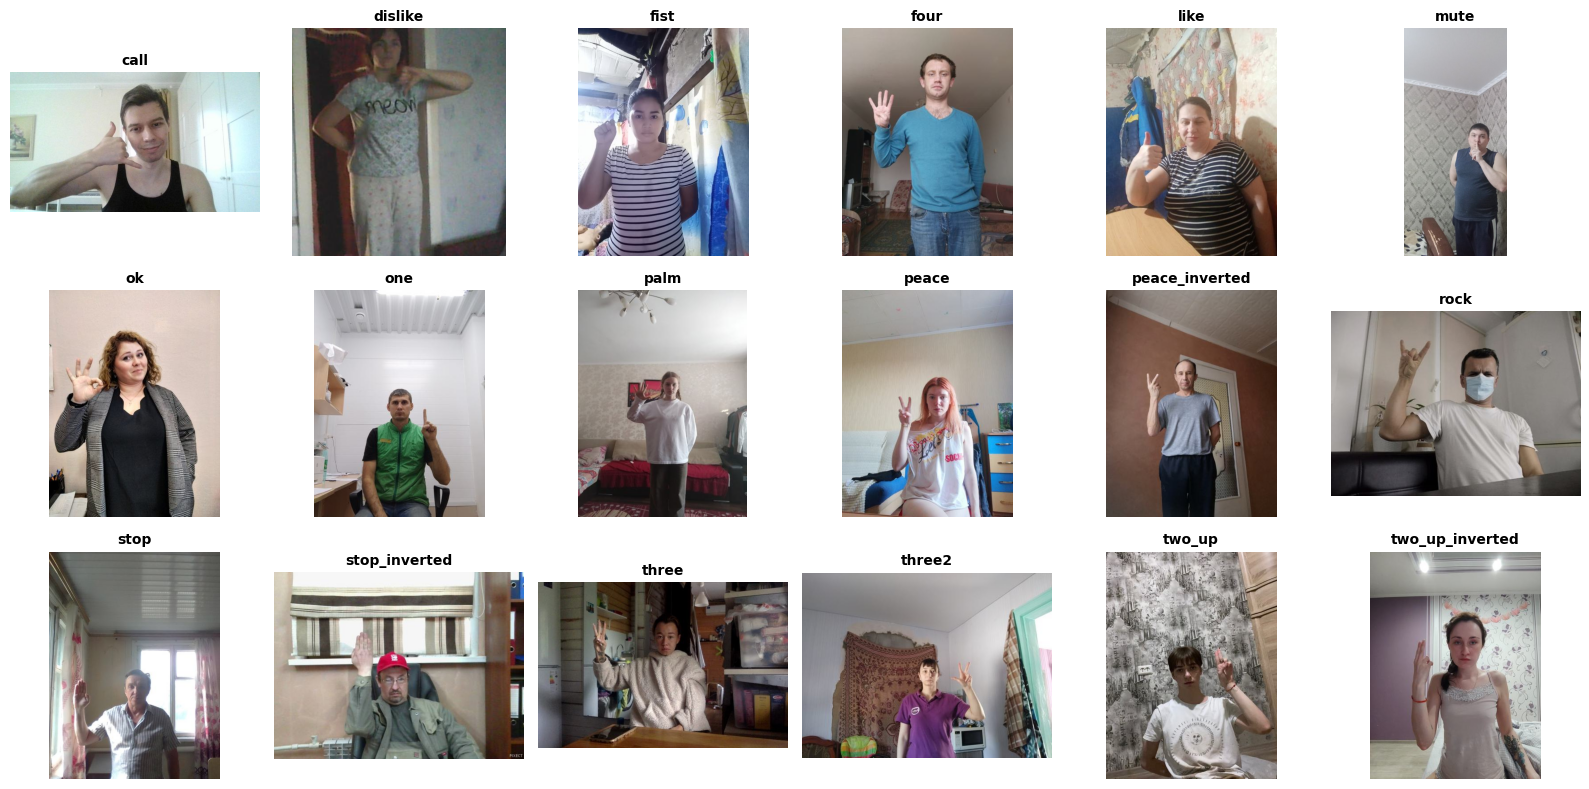

Saved sample_gestures.png


In [7]:
# Visualize sample images from each class
fig, axes = plt.subplots(3, 6, figsize=(16, 8))
axes = axes.flatten()

# Get one random image per class
for idx, cls_name in enumerate(sorted(class_names)):
    cls_idx = dataset.class_to_idx[cls_name]
    cls_images = [d for d, l in dataset.samples if l == cls_idx]
    if cls_images:
        sample_path = random.choice(cls_images)
        img = Image.open(sample_path).convert('RGB')
        
        ax = axes[idx]
        ax.imshow(img)
        ax.set_title(cls_name, fontsize=10, fontweight='bold')
        ax.axis('off')

# Hide unused subplots
for idx in range(len(class_names), len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.savefig('sample_gestures.png', dpi=100, bbox_inches='tight')
plt.show()
print("Saved sample_gestures.png")

In [8]:
# Load ViT-B/16 model
print("Loading ViT-B/16 from timm...")
model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=NUM_CLASSES)
model = model.to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model: ViT-B/16")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# Optimizer and scheduler
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
criterion = nn.CrossEntropyLoss()

print(f"\nOptimizer: AdamW (lr={LEARNING_RATE}, weight_decay={WEIGHT_DECAY})")
print(f"Scheduler: CosineAnnealing (T_max={EPOCHS})")

Loading ViT-B/16 from timm...
Model: ViT-B/16
Total parameters: 85,812,498
Trainable parameters: 85,812,498

Optimizer: AdamW (lr=3e-05, weight_decay=0.01)
Scheduler: CosineAnnealing (T_max=10)


In [ ]:
# Training loop
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    
    pbar = tqdm(loader, desc="Training", leave=False)
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
        
        pbar.set_postfix({'loss': total_loss / (total / BATCH_SIZE)})
    
    return total_loss / len(loader), correct / total

def validate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validating", leave=False):
            images, labels = images.to(device), labels.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            total_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    
    return total_loss / len(loader), correct / total

# Train model
print("\nStarting training...")
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc = 0.0

for epoch in range(EPOCHS):
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)
    scheduler.step()
    
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f}, Acc: {val_acc:.4f}")
    
    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), MODEL_CHECKPOINT)
        print(f"  ✓ Saved best model (val_acc: {val_acc:.4f})")

print(f"\nTraining complete! Best val accuracy: {best_val_acc:.4f}")


Starting training...


Training:   2%|█                                                            | 12/697 [00:28<27:04,  2.37s/it, loss=3.13]

In [ ]:
# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Loss plot
axes[0].plot(history['train_loss'], label='Train Loss', marker='o')
axes[0].plot(history['val_loss'], label='Val Loss', marker='s')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy plot
axes[1].plot(history['train_acc'], label='Train Accuracy', marker='o')
axes[1].plot(history['val_acc'], label='Val Accuracy', marker='s')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training and Validation Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_history.png', dpi=100, bbox_inches='tight')
plt.show()
print("Saved training_history.png")

In [ ]:
# Evaluate on test set
model.load_state_dict(torch.load(MODEL_CHECKPOINT, map_location=device))
model.eval()

all_preds = []
all_labels = []

print("Evaluating on test set...")
with torch.no_grad():
    for images, labels in tqdm(test_loader):
        images = images.to(device)
        
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Calculate metrics
test_acc = accuracy_score(all_labels, all_preds)
test_f1 = f1_score(all_labels, all_preds, average='weighted')

print(f"\nTest Results:")
print(f"Accuracy: {test_acc:.4f}")
print(f"Weighted F1: {test_f1:.4f}")
print(f"\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))

In [ ]:
# Plot confusion matrix
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Count'})
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Test Set')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=100, bbox_inches='tight')
plt.show()
print("Saved confusion_matrix.png")

In [ ]:
# Inference demo on random test samples
print("Generating inference demo...")

# Get random test samples
test_sample_indices = np.random.choice(len(test_indices), min(12, len(test_indices)), replace=False)

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

model.eval()
correct_count = 0

with torch.no_grad():
    for plot_idx, sample_idx in enumerate(test_sample_indices):
        ax = axes[plot_idx]
        
        # Get the actual dataset index
        actual_idx = test_indices[sample_idx]
        img_path, label = dataset.samples[actual_idx]
        
        # Load and display original image
        img_display = Image.open(img_path).convert('RGB')
        img_display_resized = img_display.resize((IMG_SIZE, IMG_SIZE))
        
        # Load and transform for prediction
        img_tensor = val_transform(img_display).unsqueeze(0).to(device)
        
        # Get prediction
        output = model(img_tensor)
        probs = torch.softmax(output, dim=1)
        pred_label = output.argmax(dim=1).item()
        confidence = probs[0, pred_label].item()
        
        # Display
        ax.imshow(img_display_resized)
        
        pred_name = class_names[pred_label]
        true_name = class_names[label]
        is_correct = pred_label == label
        color = 'green' if is_correct else 'red'
        
        if is_correct:
            correct_count += 1
        
        ax.set_title(f"True: {true_name}\nPred: {pred_name}\nConf: {confidence:.2f}", 
                    color=color, fontweight='bold', fontsize=9)
        ax.axis('off')

plt.suptitle(f'Inference Demo - Accuracy: {correct_count}/{len(test_sample_indices)}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('inference_samples.png', dpi=100, bbox_inches='tight')
plt.show()
print("Saved inference_samples.png")

print(f"\n✓ Fine-tuning complete!")
print(f"✓ Saved checkpoints/best_model.pth")
print(f"✓ Saved 3 visualization files (training_history.png, confusion_matrix.png, inference_samples.png)")

## GPU Server Deployment Guide

### Before Running on GPU Server:
1. **Upload this notebook** to your GPU server (Colab, Paperspace, AWS, etc.)
2. **Install dependencies**:
   ```bash
   pip install torch torchvision timm scikit-learn matplotlib seaborn pillow tqdm
   ```
3. **Upload dataset** or download using Kaggle API:
   ```bash
   pip install kaggle
   kaggle datasets download -d innominate817/hagrid-sample-30k-384p
   unzip hagrid-sample-30k-384p.zip -d ./data/
   ```

### Expected Training Time:
- **CPU**: ~4-6 hours (not recommended)
- **GPU (T4/V100)**: ~20-40 minutes
- **GPU (A100)**: ~10-15 minutes
- **Apple M1/M2 (MPS)**: ~30-50 minutes

### Output Files:
- `checkpoints/best_model.pth` - Best model weights
- `training_history.png` - Loss and accuracy curves
- `confusion_matrix.png` - Test set confusion matrix
- `inference_samples.png` - Sample predictions visualization
- `sample_gestures.png` - Dataset sample images

### Monitoring Training:
Watch for:
- **Overfitting**: If val_loss increases while train_loss decreases
- **Underfitting**: If both train/val accuracies are low (<60%)
- **Good fit**: Val accuracy ~75-85% for this 18-class task

### Quick Sanity Check (Optional):
To test with just 1 epoch before full training:
```python
EPOCHS = 1  # Change back to 10 for full training
```